In [ ]:
print ("welcome to Amazon product Intelligence AI")

welcome to Amazon product Intelligence AI


In [ ]:
#data Analysis Libraries
import pandas as pd
import numpy as np

#data visualization
import matplotlib.pyplot as plt
import seaborn as sns

print("all libraries imported sucessfully")


all libraries imported sucessfully


In [ ]:
!pip install -q datasets

In [ ]:
from datasets import load_dataset

print("Dataset library is ready!")

Dataset library is ready!


In [ ]:
import os

for file in os.listdir('/content'):
    print(file, os.path.getsize('/content/' + file), 'bytes')

.config 4096 bytes
ratings_Electronics (1).csv.zip 45088768 bytes
sample_data 4096 bytes


In [20]:
import zipfile

zip_path = "/content/ratings_Electronics (1).csv.zip"

print(zipfile.is_zipfile(zip_path))

False


In [21]:
import pandas as pd

file_path = "/content/ratings_Electronics (1).csv"

df = pd.read_csv(
    file_path,
    header=None,
    names=["user_id", "product_id", "rating", "timestamp"],
    encoding="latin-1",
    nrows=100000
)

print("Dataset Loaded Successfully!")
print("Dataset Shape:", df.shape)

df.head()

Dataset Loaded Successfully!
Dataset Shape: (100000, 4)


,user_id,product_id,rating,timestamp
0,AKM1MP6P0OYPR,0132793040,5.0,1365811200
1,A2CX7LUOHB2NDG,0321732944,5.0,1341100800
2,A2NWSAGRHCP8N5,0439886341,1.0,1367193600
3,A2WNBOD3WNDNKT,0439886341,3.0,1374451200
4,A1GI0U4ZRJA8WN,0439886341,1.0,1334707200


In [ ]:
print("Dataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nRating Distribution:")
print(df["rating"].value_counts().sort_index())

print("\nUnique Users:", df["user_id"].nunique())
print("Unique Products:", df["product_id"].nunique())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 4 columns):
 #   Column      Non-Null Count   Dtype  
---  ------      --------------   -----  
 0   user_id     100000 non-null  object 
 1   product_id  100000 non-null  object 
 2   rating      100000 non-null  float64
 3   timestamp   100000 non-null  int64  
dtypes: float64(1), int64(1), object(2)
memory usage: 3.1+ MB

Missing Values:
user_id       0
product_id    0
rating        0
timestamp     0
dtype: int64

Rating Distribution:
rating
1.0    10978
2.0     5461
3.0     7952
4.0    20493
5.0    55116
Name: count, dtype: int64

Unique Users: 89938
Unique Products: 6918


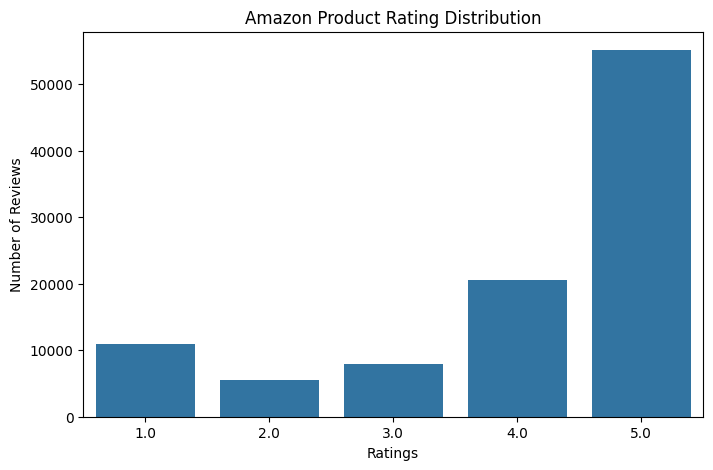

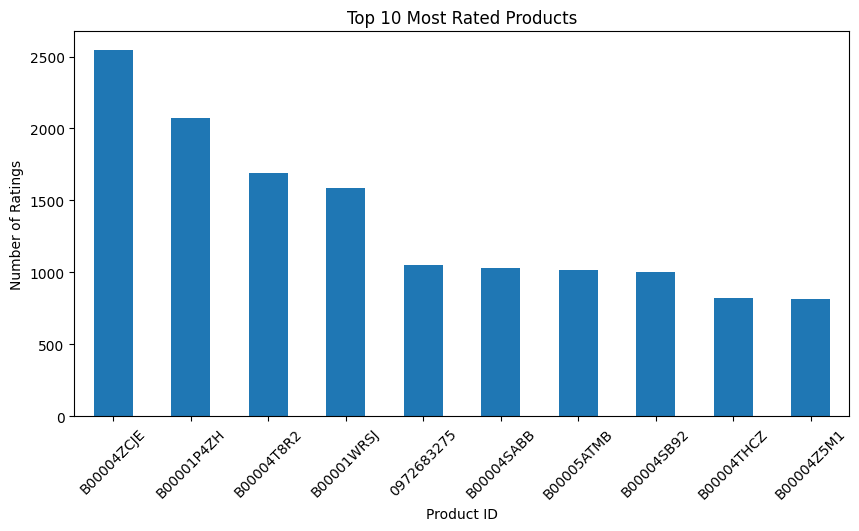

Average Rating: 4.03308


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Rating Distribution
plt.figure(figsize=(8,5))
sns.countplot(data=df, x="rating")
plt.title("Amazon Product Rating Distribution")
plt.xlabel("Ratings")
plt.ylabel("Number of Reviews")
plt.show()

# 2. Top 10 Most Rated Products
top_products = df["product_id"].value_counts().head(10)

plt.figure(figsize=(10,5))
top_products.plot(kind="bar")
plt.title("Top 10 Most Rated Products")
plt.xlabel("Product ID")
plt.ylabel("Number of Ratings")
plt.xticks(rotation=45)
plt.show()

# 3. Average Rating
print("Average Rating:", df["rating"].mean())

In [ ]:
# Calculate product-wise average rating
product_ratings = df.groupby("product_id").agg(
    average_rating=("rating", "mean"),
    total_ratings=("rating", "count")
).reset_index()

# Filter products with at least 50 ratings
popular_products = product_ratings[
    product_ratings["total_ratings"] >= 50
]

# Sort by average rating
popular_products = popular_products.sort_values(
    by=["average_rating", "total_ratings"],
    ascending=False
)

print("Top 10 Recommended Products:")

popular_products.head(10)

Top 10 Recommended Products:


,product_id,average_rating,total_ratings
6014,B000053HC5,4.945783,166
6017,B000053HH5,4.841499,347
3320,B00004TDLD,4.840517,232
3365,B00004TENT,4.823529,51
4270,B00004Y2MM,4.808824,68
4210,B00004XOM3,4.794613,297
6013,B000053HBB,4.793651,63
5646,B0000511U7,4.790055,181
5794,B0000513US,4.771084,83
4644,B00004Z5KA,4.754717,53


In [ ]:
# Create User-Product Matrix

user_product_matrix = df.pivot_table(
    index="user_id",
    columns="product_id",
    values="rating"
)

print("User-Product Matrix Created!")
print("Matrix Shape:", user_product_matrix.shape)

user_product_matrix.head()

User-Product Matrix Created!
Matrix Shape: (89938, 6918)


product_id,0132793040,0321732944,0439886341,0511189877,0528881469,0558835155,059400232X,0594012015,0594017343,0594017580,...,B00005K2R1,B00005K2S8,B00005K2SA,B00005K2SC,B00005K3AN,B00005K3KD,B00005K3KT,B00005K3LZ,B00005K47N,B00005K47X
user_id,,,,,,,,,,,,,,,,,,,,,
A001944026UMZ8T3K5QH1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
A00766851QZZUBOVF4JFT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
A01255851ZO1U93P8RKGE,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
A014623426J5CM7M12MBW,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
A01580702BRW77PSJ9X34,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
# Filter active users
user_counts = df["user_id"].value_counts()
active_users = user_counts[user_counts >= 5].index

filtered_df = df[df["user_id"].isin(active_users)]

print("Original Dataset:", df.shape)
print("Filtered Dataset:", filtered_df.shape)

Original Dataset: (100000, 4)
Filtered Dataset: (3287, 4)


In [ ]:
# Keep users with at least 5 ratings
# Keep products rated by at least 5 users

user_counts = filtered_df["user_id"].value_counts()
active_users = user_counts[user_counts >= 5].index

product_counts = filtered_df["product_id"].value_counts()
active_products = product_counts[product_counts >= 5].index

final_df = filtered_df[
    filtered_df["user_id"].isin(active_users) &
    filtered_df["product_id"].isin(active_products)
].copy()

print("Final Dataset Shape:", final_df.shape)
print("Unique Users:", final_df["user_id"].nunique())
print("Unique Products:", final_df["product_id"].nunique())

Final Dataset Shape: (973, 4)
Unique Users: 336
Unique Products: 114


In [ ]:
from sklearn.metrics.pairwise import cosine_similarity

# Create user-product matrix
user_product_matrix = final_df.pivot_table(
    index="user_id",
    columns="product_id",
    values="rating"
).fillna(0)

# Calculate user similarity
user_similarity = cosine_similarity(user_product_matrix)

print("Cosine Similarity Calculated Successfully!")
print("Similarity Matrix Shape:", user_similarity.shape)

Cosine Similarity Calculated Successfully!
Similarity Matrix Shape: (336, 336)


In [ ]:
import numpy as np

user_index = 0

similar_users = np.argsort(
    user_similarity[user_index]
)[::-1][1:6]

print("Top 5 Similar Users:")

for index in similar_users:
    print(
        user_product_matrix.index[index],
        "Similarity:",
        round(user_similarity[user_index][index], 3)
    )

Top 5 Similar Users:
AJNVX5R3TRQKN Similarity: 0.707
A3UWDEBSKQFM7V Similarity: 0.68
A2MAXHANV8EETT Similarity: 0.518
ATW2I5S6S2PFA Similarity: 0.5
A1ORUSHRRG0VWN Similarity: 0.411


In [ ]:
# Select a user
user_index = 0
selected_user = user_product_matrix.index[user_index]

# Find products already rated by this user
user_ratings = user_product_matrix.iloc[user_index]

# Get similar users' ratings
similar_user_ratings = user_product_matrix.iloc[similar_users]

# Calculate weighted average ratings
similarity_scores = user_similarity[user_index][similar_users]

weighted_ratings = np.dot(
    similarity_scores,
    similar_user_ratings.fillna(0).values
)

total_similarity = np.sum(similarity_scores)

recommended_scores = weighted_ratings / total_similarity

# Create recommendation DataFrame
recommendations = pd.DataFrame({
    "product_id": user_product_matrix.columns,
    "predicted_score": recommended_scores
})

# Remove products already rated by the selected user
recommendations = recommendations[
    user_ratings.values == 0
]

# Show top 10 recommendations
recommendations = recommendations.sort_values(
    by="predicted_score",
    ascending=False
)

print("Selected User:", selected_user)
print("\nTop 10 Personalized Recommendations:")
display(recommendations.head(10))

Selected User: A10C84Y38RT22P

Top 10 Personalized Recommendations:


,product_id,predicted_score
29,B00002JXFH,1.612088
107,B00005AW1H,1.465708
104,B00005ARK3,1.281655
55,B00004TDN2,1.004059
64,B00004VUGJ,0.966156
44,B00004SB92,0.920264
43,B00004S9AK,0.887471
62,B00004TS16,0.887471
34,B000031KIM,0.729497
16,B00000JI2C,0.583597


/tmp/ipykernel_2419/3887808092.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


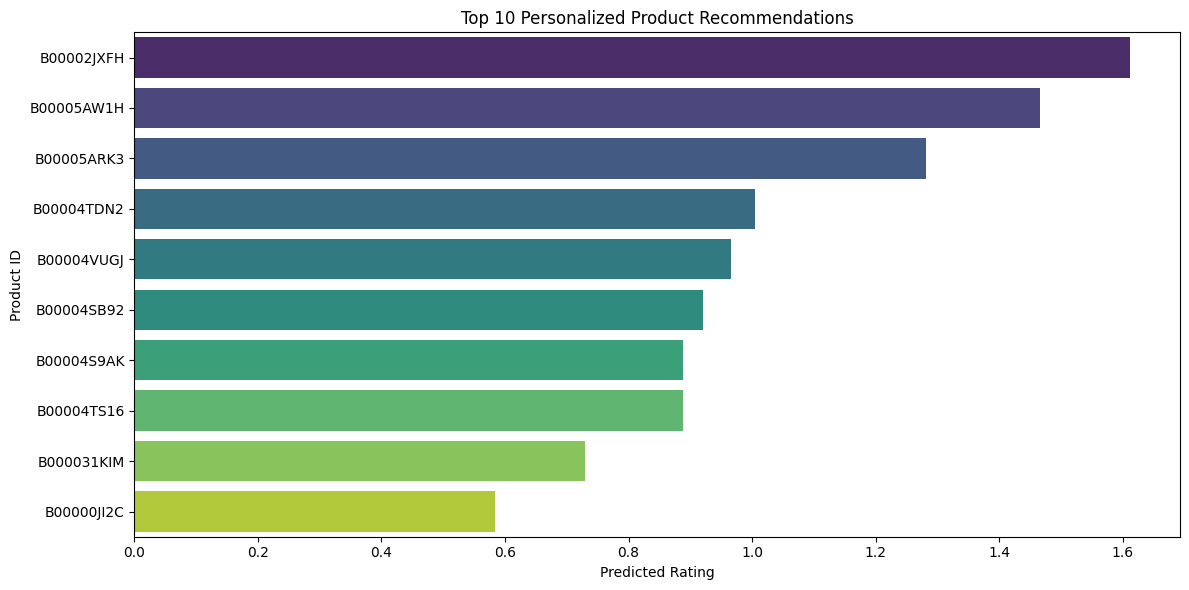

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

top_10 = recommendations.head(10)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_10,
    x="predicted_score",
    y="product_id",
    palette="viridis"
)

plt.title("Top 10 Personalized Product Recommendations")
plt.xlabel("Predicted Rating")
plt.ylabel("Product ID")

plt.tight_layout()
plt.show()

In [ ]:
# Define relevant products (actual ratings >= 4)
actual_relevant = set(
    user_ratings[user_ratings >= 4].index
)

# Get top 10 recommended products
recommended_products = set(
    recommendations.head(10)["product_id"]
)

# Calculate hits
hits = actual_relevant.intersection(recommended_products)

# Calculate Precision@10
precision_at_10 = len(hits) / 10

# Calculate Recall@10
recall_at_10 = (
    len(hits) / len(actual_relevant)
    if len(actual_relevant) > 0 else 0
)

print("Precision@10:", precision_at_10)
print("Recall@10:", recall_at_10)

Precision@10: 0.0
Recall@10: 0.0


In [ ]:
# Get Top 10 recommendations
final_recommendations = recommendations.head(10).copy()

# Save recommendations as CSV
final_recommendations.to_csv(
    "amazon_product_recommendations.csv",
    index=False
)

print("Recommendations saved successfully!")

display(final_recommendations)

Recommendations saved successfully!


,product_id,predicted_score
29,B00002JXFH,1.612088
107,B00005AW1H,1.465708
104,B00005ARK3,1.281655
55,B00004TDN2,1.004059
64,B00004VUGJ,0.966156
44,B00004SB92,0.920264
43,B00004S9AK,0.887471
62,B00004TS16,0.887471
34,B000031KIM,0.729497
16,B00000JI2C,0.583597


In [ ]:
print("=" * 55)
print(" AMAZON PRODUCT RECOMMENDATION SYSTEM")
print("=" * 55)

print("\nProject: User-Based Collaborative Filtering")

print("\nSelected User:", selected_user)

print("\nTotal Products:", len(user_product_matrix.columns))

print("Total Users:", len(user_product_matrix.index))

print("\nTop 10 Recommended Products:")
display(final_recommendations)

print("\nRecommendation Method: Collaborative Filtering")

print("Evaluation Metrics:")
print("Precision@10:", precision_at_10)
print("Recall@10:", recall_at_10)

print("\nProject Completed Successfully!")
print("=" * 55)

 AMAZON PRODUCT RECOMMENDATION SYSTEM

Project: User-Based Collaborative Filtering

Selected User: A10C84Y38RT22P

Total Products: 114
Total Users: 336

Top 10 Recommended Products:


,product_id,predicted_score
29,B00002JXFH,1.612088
107,B00005AW1H,1.465708
104,B00005ARK3,1.281655
55,B00004TDN2,1.004059
64,B00004VUGJ,0.966156
44,B00004SB92,0.920264
43,B00004S9AK,0.887471
62,B00004TS16,0.887471
34,B000031KIM,0.729497
16,B00000JI2C,0.583597



Recommendation Method: Collaborative Filtering
Evaluation Metrics:
Precision@10: 0.0
Recall@10: 0.0

Project Completed Successfully!
